[2.1] Dataframe

In [1]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Au_nanoparticle_dataset.csv')

filtered_df = df[['N_total', 'N_bulk', 'N_surface', 'R_avg']]

print("Original DataFrame shape:", df.shape)
print("Filtered DataFrame shape:", filtered_df.shape)
print("\nFirst 5 rows of filtered data:")
filtered_df.head()

Original DataFrame shape: (4000, 185)
Filtered DataFrame shape: (4000, 4)

First 5 rows of filtered data:


,N_total,N_bulk,N_surface,R_avg
0,1599,1014,585,17.3706
1,1642,1034,608,17.6061
2,4637,3365,1272,25.3692
3,7189,5292,1897,29.7011
4,11004,8508,2496,34.2831


[2.2] Display first 20



In [2]:
filtered_df.head(20)

,N_total,N_bulk,N_surface,R_avg
0,1599,1014,585,17.3706
1,1642,1034,608,17.6061
2,4637,3365,1272,25.3692
3,7189,5292,1897,29.7011
4,11004,8508,2496,34.2831
5,13375,10768,2607,36.6334
6,13795,11155,2640,37.0108
7,13947,11304,2643,37.1672
8,14020,11357,2663,37.2103
9,14056,11389,2667,37.2467


[2.3]mean, standard deviation and quartile values

In [3]:
stats_df = filtered_df.describe(percentiles=[.25, .5, .75])

stats_df.loc['std'] = filtered_df.std()

stats_df = stats_df.reindex(['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max'])

print("Complete Statistics:")
display(stats_df)

Complete Statistics:


,N_total,N_bulk,N_surface,R_avg
count,4000.000000,4000.000000,4000.00000,4000.000000
mean,3476.786500,2521.550250,955.23625,20.654363
std,3679.286769,2976.232459,721.87022,7.610716
min,236.000000,89.000000,137.00000,8.528600
25%,1061.000000,618.750000,437.00000,15.160725
50%,1867.000000,1199.000000,666.00000,18.629250
75%,4503.000000,3183.000000,1301.75000,25.525125
max,14277.000000,11580.000000,3190.00000,39.239200


[2.4]Plot the histogram in a 1x4 layout

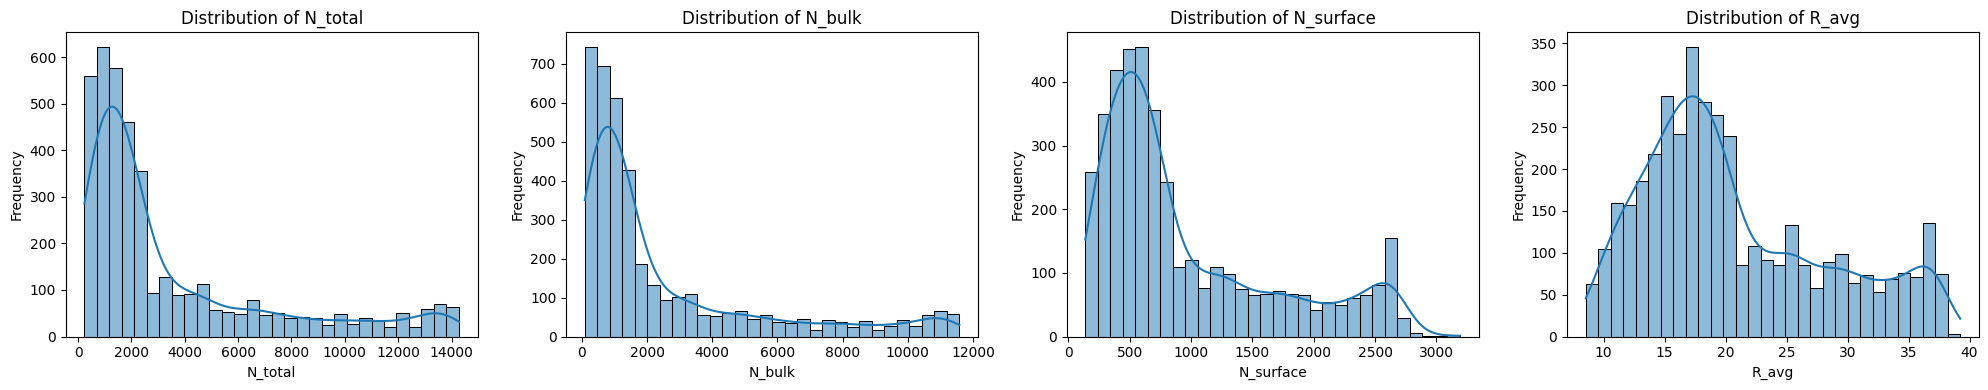

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 4))

features = ['N_total', 'N_bulk', 'N_surface', 'R_avg']

for i, feature in enumerate(features, 1):
    plt.subplot(1, 4, i)
    sns.histplot(data=filtered_df, x=feature, kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

[2.5] pairplot functionality

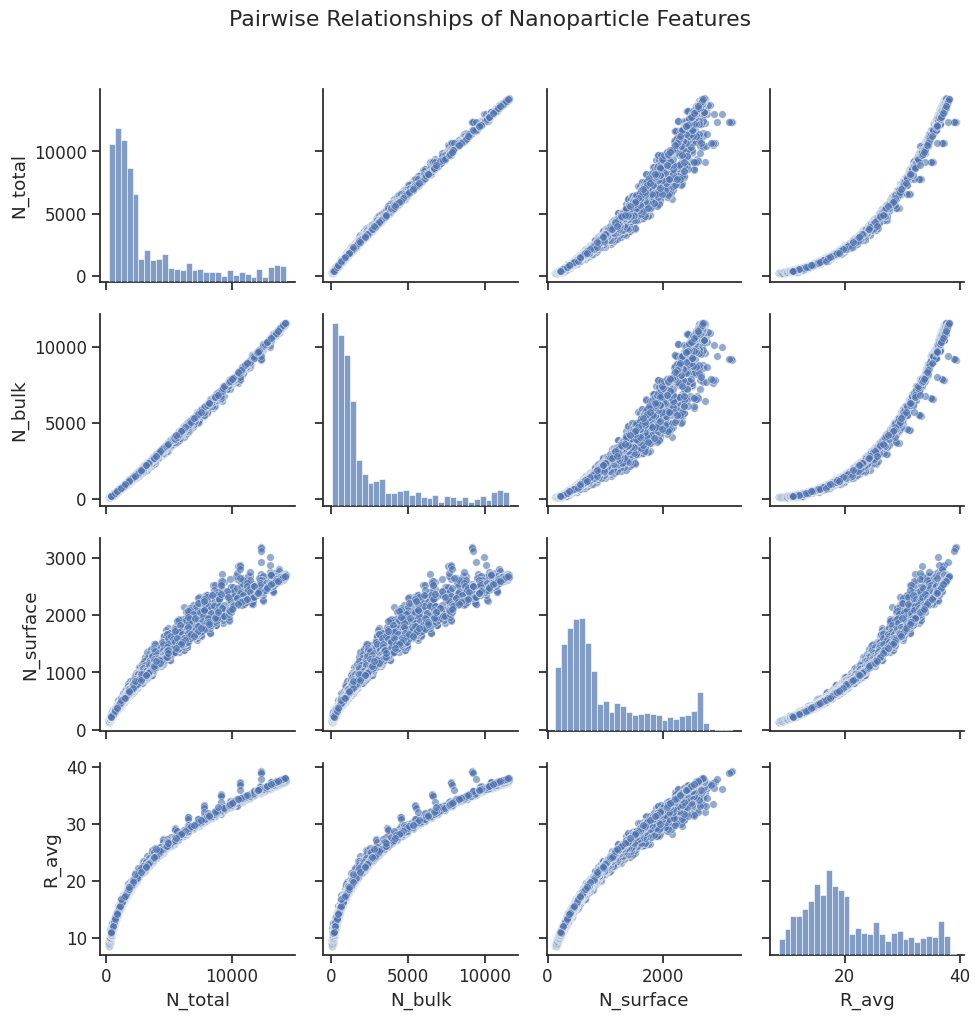

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks", font_scale=1.1)

pair_grid = sns.pairplot(filtered_df,
                         diag_kind='hist',
                         plot_kws={'alpha': 0.6, 's': 30},
                         diag_kws={'bins': 30, 'alpha': 0.7},
                         corner=False)

plt.suptitle('Pairwise Relationships of Nanoparticle Features', y=1.02)
plt.tight_layout()
plt.show()

[2.6] plots

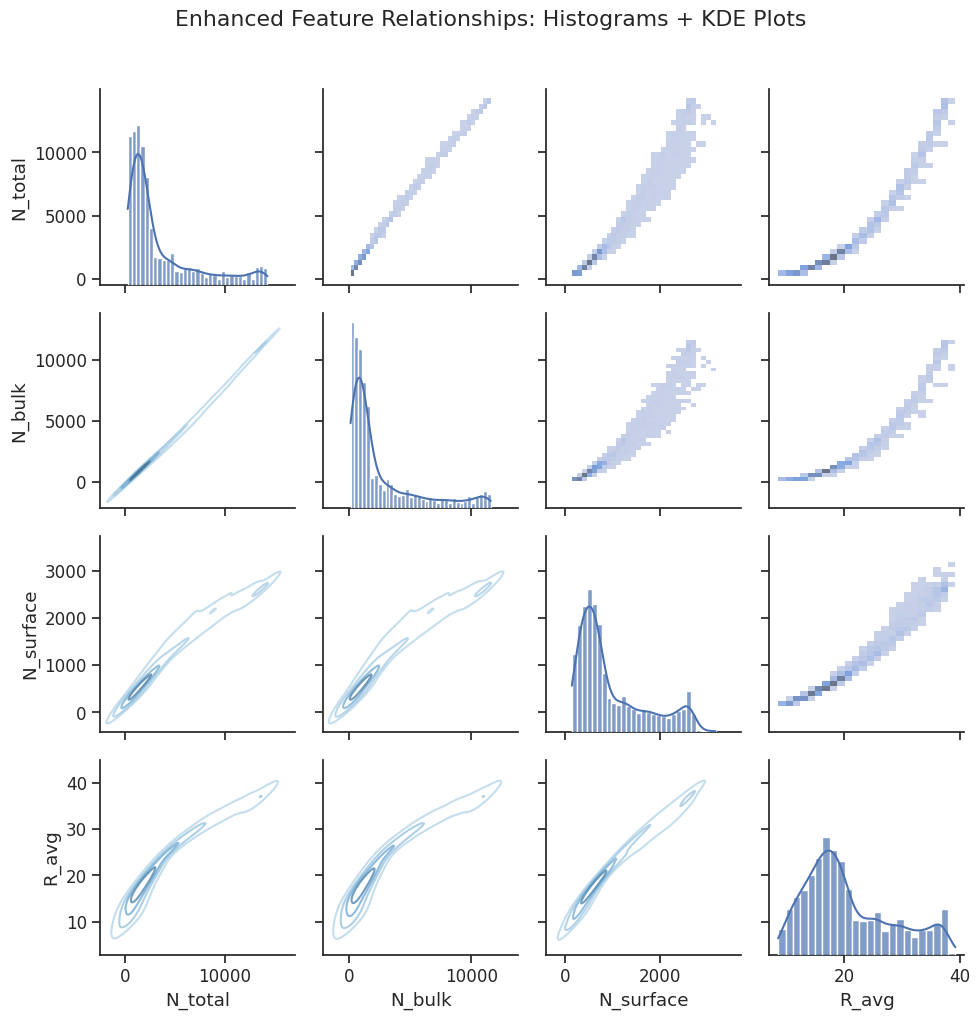

In [6]:
g = sns.PairGrid(filtered_df)

g.map_upper(sns.histplot, alpha=0.8)

g.map_diag(sns.histplot, kde=True, alpha=0.7, linewidth=1, edgecolor='white')

g.map_lower(sns.kdeplot, cmap='Blues_d', levels=5, alpha=0.7)

plt.suptitle('Enhanced Feature Relationships: Histograms + KDE Plots', y=1.02)
plt.tight_layout()
plt.show()